In [1]:
!pip install ase matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 11.9 MB/s  0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from ase.build import bulk, fcc111
from ase.calculators.emt import EMT
from ase.optimize import BFGS
from ase.filters import FrechetCellFilter

metal = "Au"
a_guess = {"Au": 4.08, "Cu": 3.61}[metal]   # starting lattice constant (Angstrom)

# Bulk reference: relax the primitive fcc cell
b = bulk(metal, "fcc", a=a_guess)
b.calc = EMT()
BFGS(FrechetCellFilter(b), logfile=None).run(fmax=0.001)

e_bulk = b.get_potential_energy() / len(b)   # energy per atom (eV)
a0 = (4 * b.get_volume()) ** (1 / 3)         # cubic lattice constant (Angstrom)

print(f"Bulk energy per atom: {e_bulk:.4f} eV")
print(f"Lattice constant a0: {a0:.4f} Angstrom")

Bulk energy per atom: -0.0001 eV
Lattice constant a0: 4.0562 Angstrom


3 layers: 0.517 J/m^2
4 layers: 0.513 J/m^2
5 layers: 0.514 J/m^2
6 layers: 0.514 J/m^2
7 layers: 0.514 J/m^2
8 layers: 0.514 J/m^2
9 layers: 0.514 J/m^2


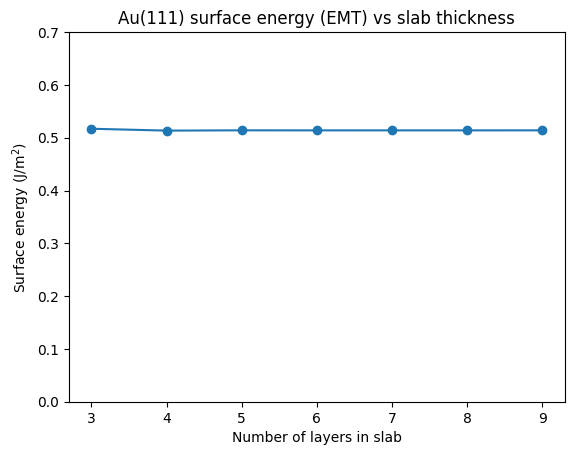

In [5]:
EV_PER_A2_TO_J_PER_M2 = 16.0218   # unit conversion

def surface_energy(n_layers):
    slab = fcc111(metal, size=(1, 1, n_layers), a=a0, vacuum=10.0, orthogonal=False)
    slab.calc = EMT()
    BFGS(slab, logfile=None).run(fmax=0.01)
    e_slab = slab.get_potential_energy()
    area = np.linalg.norm(np.cross(slab.cell[0], slab.cell[1]))
    gamma = (e_slab - len(slab) * e_bulk) / (2 * area)
    return gamma * EV_PER_A2_TO_J_PER_M2

layers = [3, 4, 5, 6, 7, 8, 9]
gammas = [surface_energy(n) for n in layers]

for n, g in zip(layers, gammas):
    print(f"{n} layers: {g:.3f} J/m^2")

plt.plot(layers, gammas, "o-")
plt.xlabel("Number of layers in slab")
plt.ylabel("Surface energy (J/m$^2$)")
plt.title(f"{metal}(111) surface energy (EMT) vs slab thickness")
plt.ylim(0, 0.7)
plt.savefig("surface_energy_vs_layers.png", dpi=200, bbox_inches="tight")
plt.show()